In [23]:
import sys

sys.path.append("/home/pop533611/thesis")
import mongoConnect as mc

In [24]:
records = mc.read_records("citedData")
refCount = []
for record in records:
    refCount.append(len(record["ref"]))

print(len(refCount))

1176647


In [22]:
file = open('refCount.txt','w')
file.writelines(str(refCount))
file.close()

In [26]:
total = []
data = []
refCount = [2,3,4]

for field in ["Medicine", "Physics", "Biology", "Computer Science", "Mathematics", "Chemistry", "Materials Science"]:
    for year in [(1996, 2000), (2001, 2005), (2006, 2010), (2011, 2015), (2016, 2020)]:
        for c in refCount:
            paper_query = {
                "field": field,
                "year": {"$gte": year[0], "$lte": year[1]}
            }
            
            papers = mc.get_records("papers", paper_query)
            # print)
            
            cited_data_query = {
                "ref": {"$exists": True, "$size": c},
                "paperId": {"$in": [paper["_id"] for paper in papers]}
            }
            
            records = mc.get_records("citedData", cited_data_query)
   
            for record in records:
                print(record)

In [33]:
# Specify the two collections
db = mc.get_connect()
papers_collection = db["papers"]
cited_data_collection = db["citedData"]

# Define the field and year range you want to filter by
field = "Medicine"
year_range = {"$gte": 1996, "$lte": 2000}

# Perform the aggregation
pipeline = [
    {
        "$match": {
            "field": field,
            "year": year_range
        }
    },
    {
        "$lookup": {
            "from": "citedData",
            "localField": "paperId",
            "foreignField": "_id",
            "as": "cited_data"
        }
    },
    {
        "$unwind": "$cited_data"
    },
    {
        "$project": {
            "_id": 0,  # Exclude the _id field if desired
            "paperId": 1,  # Include the paperId field
            "cited_data_id": "$cited_data._id"  # Access the _id field
        }
    }
]


result = list(papers_collection.aggregate(pipeline))  # Convert to a list

# Iterate through the results and print them
for doc in result:
    print(doc)

In [32]:
print(result)

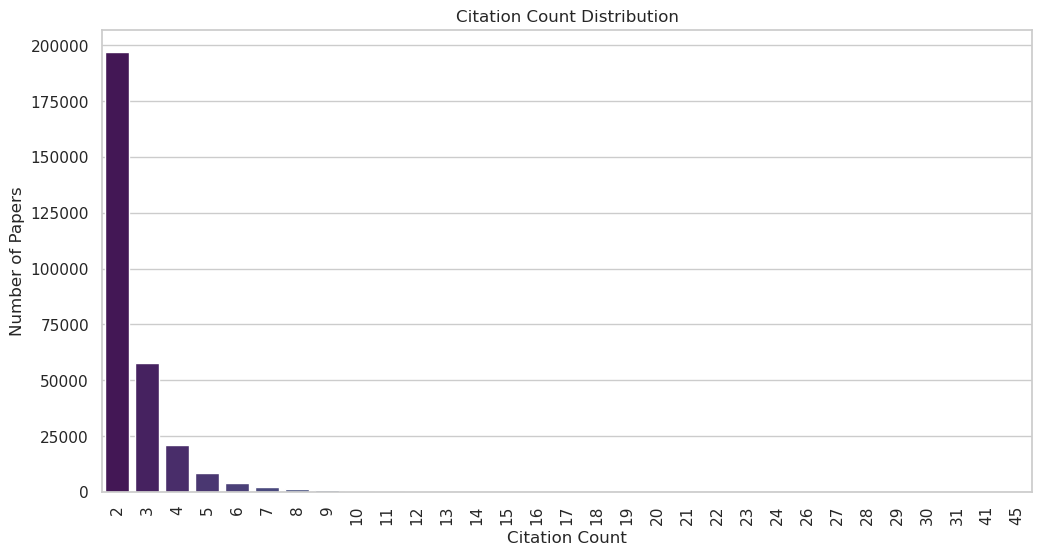

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Your data
data = [{2: 197110}, {3: 57611}, {4: 20951}, {5: 8608}, {6: 4073}, {7: 2082}, {8: 1095}, {9: 707}, {10: 366}, {11: 275}, {12: 158}, {13: 90}, {14: 82}, {15: 48}, {16: 30}, {17: 24}, {18: 27}, {19: 16}, {20: 5}, {21: 8}, {22: 5}, {23: 3}, {24: 3}, {26: 4}, {27: 1}, {28: 1}, {29: 1}, {30: 1}, {31: 1}, {41: 1}, {45: 1}]

# Extract citation counts and paper counts from the data
citation_counts = [list(item.keys())[0] for item in data]
paper_counts = [list(item.values())[0] for item in data]

# Set a seaborn style
sns.set(style="whitegrid")

# Create a bar plot using seaborn
plt.figure(figsize=(12, 6))  # Adjust the figure size
ax = sns.barplot(x=citation_counts, y=paper_counts, palette="viridis")
ax.set(xlabel='Citation Count', ylabel='Number of Papers')
plt.title('Citation Count Distribution')

# Rotate x-axis labels for better readability
plt.xticks(rotation=90)

# Display the plot
plt.show()


In [15]:
vals = []

for t in total:
    vals.append(t)


In [17]:
print(total)

[883259, 197110, 57611, 20951, 8608, 4073, 2082, 1095, 707, 366, 275, 158, 90, 82, 48, 30, 24, 27, 16, 5, 8, 5, 3, 3, 4, 1, 1, 1, 1, 1, 1, 1]


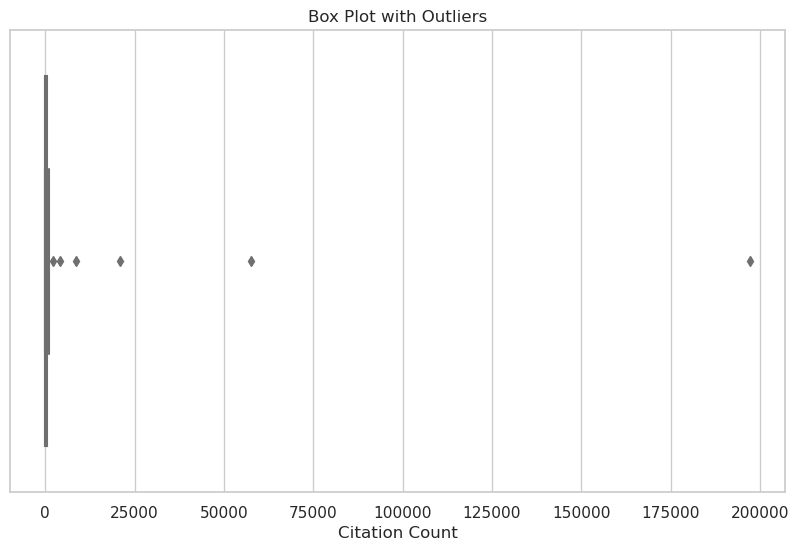

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
6
# Your data
data = [197110, 57611, 20951, 8608, 4073, 2082, 1095, 707, 366, 275, 158, 90, 82, 48, 30, 24, 27, 16, 5, 8, 5, 3, 3, 4, 1, 1, 1, 1, 1, 1, 1]

# Create a box plot with outliers
plt.figure(figsize=(10, 6))  # Adjust the figure size
sns.set(style="whitegrid")  # Set seaborn style

sns.boxplot(x=data, color="skyblue")  # Create the box plot

plt.title('Box Plot with Outliers')
plt.xlabel('Citation Count')

# Show the plot
plt.show()
